In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("diabetes_risk.csv")
df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

In [4]:
df.isnull().sum()

Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

In [5]:
df.shape

(520, 17)

In [6]:
from sklearn.preprocessing import LabelEncoder

In [7]:
encoder = LabelEncoder()
for i in df.columns[1:]:
    df[i]= encoder.fit_transform(df[i])

df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [9]:
x= df.iloc[:,:-1]
y= df['class']

In [10]:
x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.8,random_state= 0)

In [11]:
rf = RandomForestClassifier(n_estimators= 10)
rf.fit(x_train, y_train)

RandomForestClassifier(n_estimators=10)

In [12]:
y_pred = rf.predict(x_test)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        64

    accuracy                           1.00       104
   macro avg       1.00      1.00      1.00       104
weighted avg       1.00      1.00      1.00       104



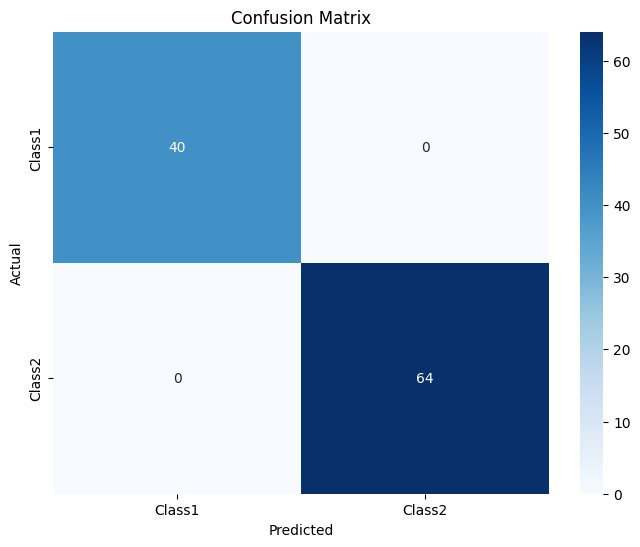

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming y_test and y_pred are already defined
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="Blues", xticklabels=['Class1', 'Class2'], yticklabels=['Class1', 'Class2'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


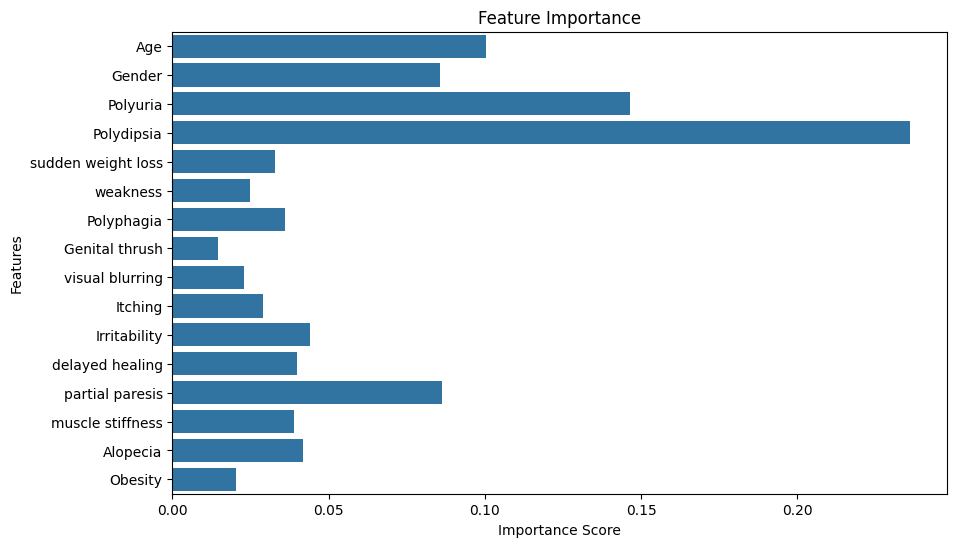

In [15]:
importance = rf.feature_importances_
features = x.columns
plt.figure(figsize=(10, 6))
sns.barplot(x=importance, y=features)
plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [16]:
print("Unique values in the target:", y_train.unique())
print(y_train.value_counts())
from sklearn.metrics import classification_report
y_train_pred = rf.predict(x_train)
print("Training Classification Report:")
print(classification_report(y_train, y_train_pred))

print("Predicted classes in test set:", set(y_pred))


Unique values in the target: [0 1]
class
1    256
0    160
Name: count, dtype: int64
Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       160
           1       1.00      1.00      1.00       256

    accuracy                           1.00       416
   macro avg       1.00      1.00      1.00       416
weighted avg       1.00      1.00      1.00       416

Predicted classes in test set: {0, 1}


In [ ]:
import joblib
joblib.dump(rf, "random_forest_model.pkl")
print("Model saved as 'random_forest_model.pkl'")


Model saved as 'random_forest_model.pkl'


In [ ]:
from sklearn.tree import export_graphviz
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Access the first tree in the Random Forest
first_tree = rf.estimators_[0]  # Extract the first decision tree

# Option 1: Visualize using `plot_tree`
plt.figure(figsize=(20, 10))
plot_tree(first_tree, feature_names=x_train.columns, class_names=str(rf.classes_), filled=True, rounded=True)
plt.title("Decision Tree from Random Forest")
plt.show()

# Option 2: Export using Graphviz for detailed visualization
export_graphviz(
    first_tree,
    out_file="tree.dot",  # Output file
    feature_names=x_train.columns,  # Feature names
    class_names=[str(cls) for cls in rf.classes_],  # Class names
    rounded=True,
    filled=True
)

# Convert DOT file to a visual file (e.g., PNG) using Graphviz CLI
# Command: `dot -Tpng tree.dot -o tree.png`
print("Tree visualization saved as 'tree.dot'. Convert it to an image using Graphviz.")
